<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_5_DepthAnything_overlay_DepthVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TUM RGB-D — freiburg1_xyz

The TUM RGB-D dataset provides synchronized RGB video + depth video from a Kinect sensor. The specific sequence freiburg1_xyz is particularly convenient:

* Duration: 30.09 seconds
* With ground truth: 30.00 seconds
* RGB movie available
* Depth movie available
* Indoor office scene
* Kinect RGB-D data
* The camera moves through the scene, so there is meaningful depth variation
* The RGB and depth streams can be synchronized.

Source: https://cvg.cit.tum.de/data/datasets/rgbd-dataset/download

The goal is to:

* Select one RGB frame.
* Generate its depth map.
* Colorize the depth using a colormap.
* Create overlays with 5 different alpha values.
* Save and display the results.

In [9]:
import cv2
import os

import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

In [3]:
# Set up Depth Anything V2 Small

model_name = "depth-anything/Depth-Anything-V2-Small-hf"

processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForDepthEstimation.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.eval()

print("Device:", device)
print("Model:", model_name)

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Device: cpu
Model: depth-anything/Depth-Anything-V2-Small-hf


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Generate the colorized depth

# Open the TUM RGB video
video_path = "/content/drive/MyDrive/Computer Vision/05/TUM RGB-D dataset/rgbd_dataset_freiburg1_xyz-rgb.avi"

cap = cv2.VideoCapture(video_path)

# Read one frame
ret, frame = cap.read()
cap.release()

if not ret:
    raise ValueError("Could not read the video frame.")

# OpenCV reads BGR, convert to RGB
rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Convert to PIL image for Depth Anything
image = Image.fromarray(rgb_frame)

# Depth Anything preprocessing
inputs = processor(images=image, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}

# Depth prediction
with torch.no_grad():
    outputs = model(**inputs)

# Get predicted depth
predicted_depth = outputs.predicted_depth

# Resize depth to original image size
depth = torch.nn.functional.interpolate(
    predicted_depth.unsqueeze(1),
    size=(rgb_frame.shape[0], rgb_frame.shape[1]),
    mode="bicubic",
    align_corners=False
).squeeze().cpu().numpy()

print("RGB shape:", rgb_frame.shape)
print("Depth shape:", depth.shape)

RGB shape: (480, 640, 3)
Depth shape: (480, 640)


**RGB Image + Colorized Depth → Depth Overlay**

The original RGB image remains visible, while the depth information is shown as colors on top of it.

### Alpha

**Alpha** controls how much of the depth image appears in the final overlay.

A common formula is:

$$
\text{Overlay} = (1-\alpha)\times RGB + \alpha\times Depth + γ
$$

So:

- **α = 0** → only the original RGB image
- **α = 0.2** → mostly RGB, small amount of depth
- **α = 0.5** → RGB and depth have equal contribution
- **α = 0.8** → mostly depth, less RGB
- **α = 1** → only the colorized depth image

γ is gamma.

gamma = 0 means no additional brightness is added to the resulting image.

gamma = 20 would make the resulting image brighter.

In [6]:
# Colorize the depth and create overlays

# Normalize depth to 0-255
depth_normalized = cv2.normalize(
    depth,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Apply color map
depth_colorized = cv2.applyColorMap(
    depth_normalized,
    cv2.COLORMAP_PLASMA
)

# Convert BGR to RGB for displaying with matplotlib
depth_colorized_rgb = cv2.cvtColor(
    depth_colorized,
    cv2.COLOR_BGR2RGB
)

# Alpha values to test
alphas = [0.2, 0.4, 0.5, 0.7, 0.8]

# Create overlays
overlays = []

for alpha in alphas:
    overlay = cv2.addWeighted(
        rgb_frame,
        1 - alpha,
        depth_colorized_rgb,
        alpha,
        0
    )
    overlays.append(overlay)

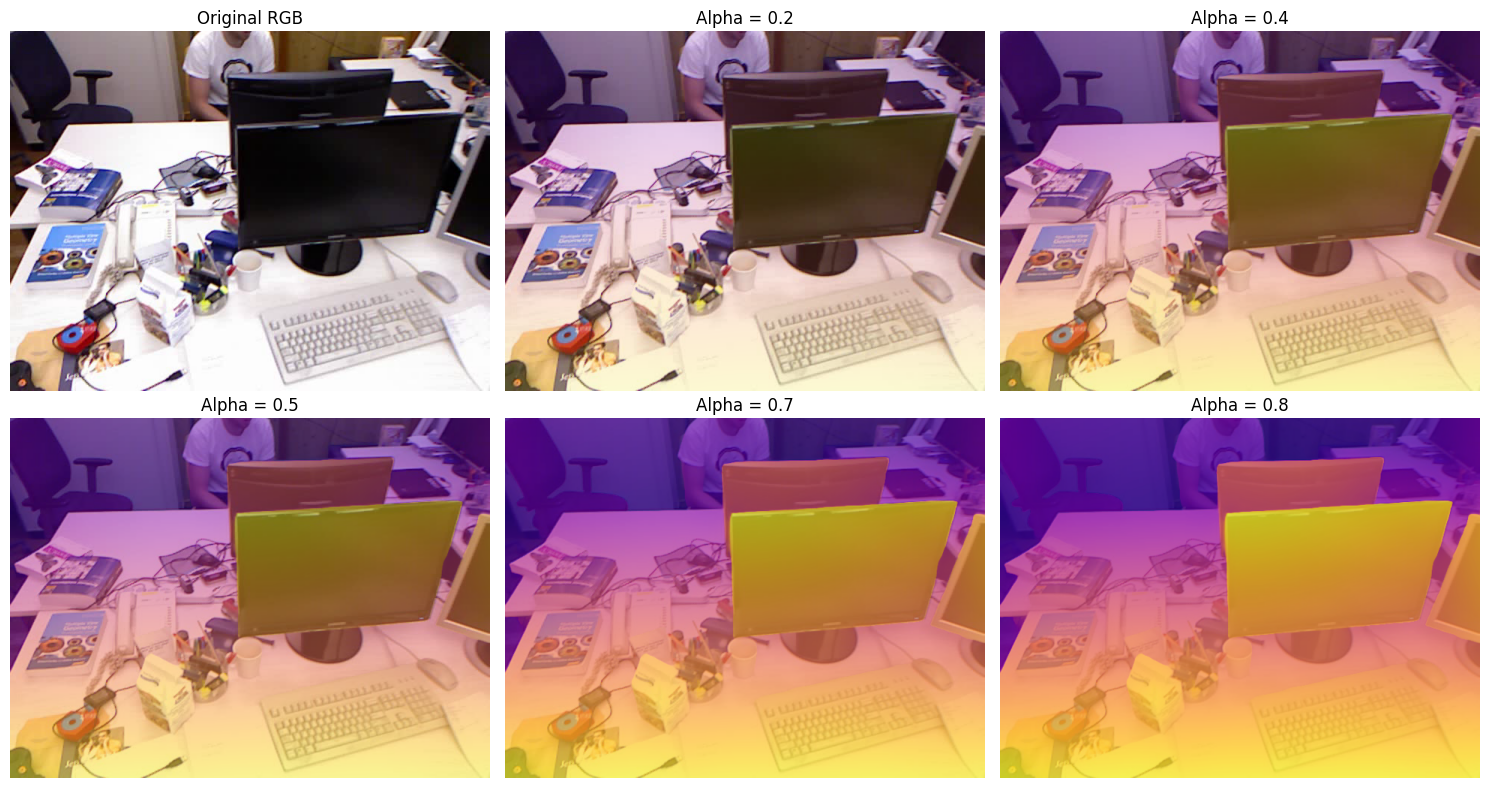

In [ ]:
# Display the results

plt.figure(figsize=(15, 8))

# Original RGB
plt.subplot(2, 3, 1)
plt.imshow(rgb_frame)
plt.title("Original RGB")
plt.axis("off")

# Five alpha values
for i, (alpha, overlay) in enumerate(zip(alphas, overlays), start=2):
    plt.subplot(2, 3, i)
    plt.imshow(overlay)
    plt.title(f"Alpha = {alpha}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Save the five images

output_dir = "/content/drive/MyDrive/Computer Vision/05/Overlay_DepthVisualization"

for alpha, overlay in zip(alphas, overlays):
    filename = f"depth_overlay_alpha_{alpha}.png"
    output_path = output_dir + filename

    # Convert RGB to BGR before saving with OpenCV
    cv2.imwrite(
        output_path,
        cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
    )

print("All overlay images saved.")

All overlay images saved.


## An interactive alpha slider

In [8]:
%pip install -q ipywidgets

from google.colab import output
output.enable_custom_widget_manager()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 77.1 MB/s eta 0:00:00


In [11]:
# Alpha slider
alpha_slider = widgets.FloatSlider(
    value=0.4,
    min=0.0,
    max=1.0,
    step=0.05,
    description='Alpha:',
    continuous_update=True,
    readout_format='.2f',
    layout=widgets.Layout(width='500px')
)

# Output area for the updated image
image_output = widgets.Output()

def update_overlay(change=None):
    alpha = alpha_slider.value

    overlay = cv2.addWeighted(
        rgb_frame, 1 - alpha,
        depth_colorized_rgb, alpha,
        0
    )

    # Refresh the image whenever alpha changes
    with image_output:
        clear_output(wait=True)

        plt.figure(figsize=(10, 6))
        plt.imshow(overlay)
        plt.title(f'Depth Overlay - Alpha = {alpha:.2f}')
        plt.axis('off')
        plt.show()

# Connect slider to the update function
alpha_slider.observe(update_overlay, names='value')

# Display controls and initial image
display(alpha_slider, image_output)
update_overlay()


FloatSlider(value=0.4, description='Alpha:', layout=Layout(width='500px'), max=1.0, step=0.05)

Output()